# Regression Model

Predicting Failure Probability of Machine

## Setup and Data Loading

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import GroupKFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

current_dir = Path.cwd()
project_root = current_dir if (current_dir / "src").exists() else current_dir.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.utils import load_processed_data, get_train_test_splits, PROJECT_ROOT, RANDOM_STATE

print("Import and Setup successfully.")

Import and Setup successfully.


In [2]:
df = load_processed_data()
df.head()

,Machine_ID,Temp_C,Vibration_mm_s,Pressure_Bar,Acoustic_dB,Inspection_Duration_min,Downtime_Cost_USD,Technician_Availability_pct,Failure_Prob,Maintenance_Priority,Severity_Index,Resource_Risk
0,M004,70.415631,3.036378,5.582562,74.494678,68,3112,99,0.48,2,213.808461,31.434340
1,M006,74.509666,2.787866,4.916866,64.017351,127,522,63,0.50,2,207.722958,8.285713
2,M009,78.724957,2.067099,4.597601,68.772382,68,836,84,0.47,2,162.732294,9.952380
3,M006,76.677258,1.998635,5.012083,76.909872,142,3799,80,0.48,2,153.249820,47.487494
4,M009,53.381545,3.844676,5.176345,84.855886,88,2710,78,0.51,2,205.234753,34.743585


## Model Selection

Feature set follows from two prior findings. First, `Pressure_Bar` (no correlation with `Failure_Prob` in any quantile bin) and `Resource_Risk` (correlation 0.91 with `Downtime_Cost_USD`, redundant) are excluded on empirical grounds. Second, `Technician_Availability_pct`, `Downtime_Cost_USD`, and `Inspection_Duration_min` are excluded on causal grounds: staffing and cost variables have no plausible physical mechanism affecting a machine's internal failure probability. Supporting evidence: `Technician_Availability_pct` correlates near zero with every physical sensor reading (|r| < 0.05) while correlating -0.28 directly with `Failure_Prob` — a pattern consistent with the target's generating formula including this term directly, bypassing any physical pathway through the sensors.

Three foundational models are compared — Linear Regression, Random Forest, Gradient Boosting — using `GroupKFold` grouped by `Machine_ID` to prevent same-machine rows from appearing in both training and validation folds.

Feature sets differ by model family. Linear Regression receives 3 raw sensor readings (`Temp_C`, `Vibration_mm_s`, `Acoustic_dB`); tree-based models additionally receive `Severity_Index` (`Temp_C × Vibration_mm_s`). Justification: for Linear Regression, including versus excluding `Severity_Index` changes test R² by < 0.0001 (0.9199 either way) — a linear model cannot exploit a pre-multiplied interaction term beyond what its own linear combination of the raw components already captures. For Random Forest, the same comparison shows a small but consistent gain (test R² 0.8967 → 0.9011) — tree splits approximate a multiplicative interaction poorly without an explicit feature for it. Gradient Boosting is included in the tree-feature group for consistency with Random Forest; its own with/without comparison was inconclusive (mixed CV/test direction), so the decision defaults to the tree-family rationale rather than treating it as a special case.

In [3]:
splits = get_train_test_splits()
X_train_full, X_test_full, y_train_r, y_test_r = splits["regression"]
groups_train = df.loc[X_train_full.index, "Machine_ID"]

LINEAR_FEATURES = ["Temp_C", "Vibration_mm_s", "Acoustic_dB"]
TREE_FEATURES = LINEAR_FEATURES + ["Severity_Index"]

print(f"Linear Regression features ({len(LINEAR_FEATURES)}): {LINEAR_FEATURES}")
print(f"Tree-based model features ({len(TREE_FEATURES)}): {TREE_FEATURES}")

Linear Regression features (3): ['Temp_C', 'Vibration_mm_s', 'Acoustic_dB']
Tree-based model features (4): ['Temp_C', 'Vibration_mm_s', 'Acoustic_dB', 'Severity_Index']


In [4]:
candidate_models = {
    "Linear Regression": (Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]), LINEAR_FEATURES),
    "Random Forest": (RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE), TREE_FEATURES),
    "Gradient Boosting": (GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=RANDOM_STATE), TREE_FEATURES),
}

gkf = GroupKFold(n_splits=5)
scoring = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}

In [5]:
comparison_rows = []
for name, (model, feats) in candidate_models.items():
    Xtr = X_train_full[feats]
    cv = cross_validate(model, Xtr, y_train_r, groups=groups_train, cv=gkf, scoring=scoring)
    comparison_rows.append({
        "Model": name,
        "Features": len(feats),
        "CV_RMSE": -cv["test_rmse"].mean(),
        "CV_MAE": -cv["test_mae"].mean(),
        "CV_R2": cv["test_r2"].mean(),
    })

comparison_df = pd.DataFrame(comparison_rows).sort_values("CV_RMSE").reset_index(drop=True)
comparison_df

,Model,Features,CV_RMSE,CV_MAE,CV_R2
0,Linear Regression,3,0.014722,0.012626,0.934426
1,Gradient Boosting,4,0.016731,0.013792,0.915291
2,Random Forest,4,0.017545,0.014411,0.906802


In [6]:
best_model_name = comparison_df.loc[0, "Model"]
print(f"Selected model (lowest CV RMSE, grouped by Machine_ID): {best_model_name}")

Selected model (lowest CV RMSE, grouped by Machine_ID): Linear Regression


## Baseline Training and Evaluation

In [7]:
def evaluate_model(model, X_train, y_train, X_test, y_test, model_name):
    """Fits, predicts, and reports train/test metrics (train metrics reveal overfitting)."""
    model.fit(X_train, y_train)
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)
    metrics = {
        "Train RMSE": root_mean_squared_error(y_train, y_pred_train),
        "Test RMSE": root_mean_squared_error(y_test, y_pred_test),
        "Train MAE": mean_absolute_error(y_train, y_pred_train),
        "Test MAE": mean_absolute_error(y_test, y_pred_test),
        "Train R2": r2_score(y_train, y_pred_train),
        "Test R2": r2_score(y_test, y_pred_test),
    }
    print(f"--- {model_name} Performance ---")
    print(f"RMSE (Test): {metrics['Test RMSE']:.4f}")
    print(f"MAE (Test):  {metrics['Test MAE']:.4f}")
    print(f"R2 (Test):   {metrics['Test R2']:.4f}")
    print(f"Train/Test R2 gap: {metrics['Train R2'] - metrics['Test R2']:.4f}")
    print("-" * 30)
    return metrics

In [8]:
best_model_obj, best_features = candidate_models[best_model_name]
X_train_r = X_train_full[best_features]
X_test_r = X_test_full[best_features]
baseline_metrics = evaluate_model(best_model_obj, X_train_r, y_train_r, X_test_r, y_test_r, f"{best_model_name} (baseline)")

--- Linear Regression (baseline) Performance ---
RMSE (Test): 0.0152
MAE (Test):  0.0134
R2 (Test):   0.9199
Train/Test R2 gap: 0.0152
------------------------------


## Hyperparameter Tuning

Tuning depends on which model won the comparison above. Linear Regression has no hyperparameters (closed-form OLS solution) — if selected, no tuning step applies. If a tree-based model wins instead, its hyperparameters are tuned via `GridSearchCV` using the same `GroupKFold` split as the comparison stage, not a plain ungrouped CV.

In [9]:
tree_param_grids = {
    "Random Forest": (RandomForestRegressor(random_state=RANDOM_STATE),
                       {"n_estimators": [100, 200], "max_depth": [None, 10, 20]}),
    "Gradient Boosting": (GradientBoostingRegressor(random_state=RANDOM_STATE),
                           {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "max_depth": [2, 3]}),
}

if best_model_name == "Linear Regression":
    print("Linear Regression has no hyperparameters to tune (closed-form OLS, no regularization term).")
    final_model = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])
    final_model_name = "Linear Regression"
    final_model.fit(X_train_r, y_train_r)
else:
    print(f"{best_model_name} won. Tuning via GridSearchCV with GroupKFold (grouped by Machine_ID)...")
    estimator, param_grid = tree_param_grids[best_model_name]
    search = GridSearchCV(estimator, param_grid, cv=gkf, scoring="neg_root_mean_squared_error", n_jobs=-1)
    search.fit(X_train_r, y_train_r, groups=groups_train)
    final_model = search.best_estimator_
    final_model_name = f"{best_model_name} (tuned)"
    print(f"Best params: {search.best_params_} | CV RMSE: {-search.best_score_:.6f}")

print(f"\nFinal selected model: {final_model_name}")

Linear Regression has no hyperparameters to tune (closed-form OLS, no regularization term).

Final selected model: Linear Regression


## Model Evaluation & Error Analysis

In [10]:
final_metrics = evaluate_model(final_model, X_train_r, y_train_r, X_test_r, y_test_r, final_model_name)

--- Linear Regression Performance ---
RMSE (Test): 0.0152
MAE (Test):  0.0134
R2 (Test):   0.9199
Train/Test R2 gap: 0.0152
------------------------------


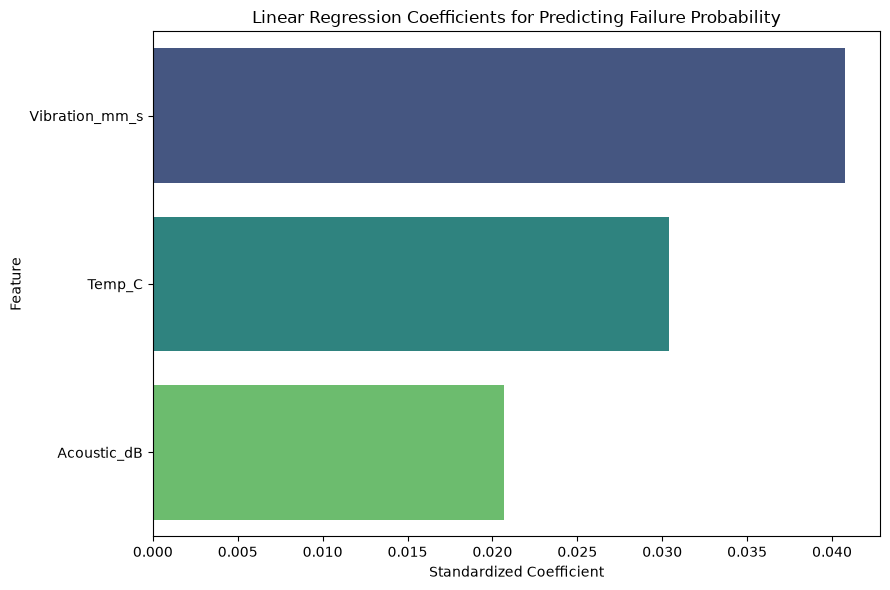

In [11]:
is_linear = hasattr(final_model, "named_steps") and hasattr(final_model.named_steps.get("model"), "coef_")
fig, ax = plt.subplots(figsize=(9, 6))
if is_linear:
    fitted = final_model.named_steps["model"]
    imp_df = pd.DataFrame({"Feature": X_train_r.columns, "Value": fitted.coef_}).sort_values("Value", key=abs, ascending=False)
    sns.barplot(data=imp_df, x="Value", y="Feature", hue="Feature", palette="viridis", legend=False, ax=ax)
    ax.set_xlabel("Standardized Coefficient")
    ax.set_title(f"{final_model_name} Coefficients for Predicting Failure Probability")
else:
    model_for_importance = final_model.named_steps["model"] if hasattr(final_model, "named_steps") else final_model
    imp_df = pd.DataFrame({"Feature": X_train_r.columns, "Value": model_for_importance.feature_importances_}).sort_values("Value", ascending=False)
    sns.barplot(data=imp_df, x="Value", y="Feature", hue="Feature", palette="viridis", legend=False, ax=ax)
    ax.set_xlabel("Relative Importance")
    ax.set_title(f"{final_model_name} Feature Importances for Predicting Failure Probability")
plt.tight_layout()
plt.show()

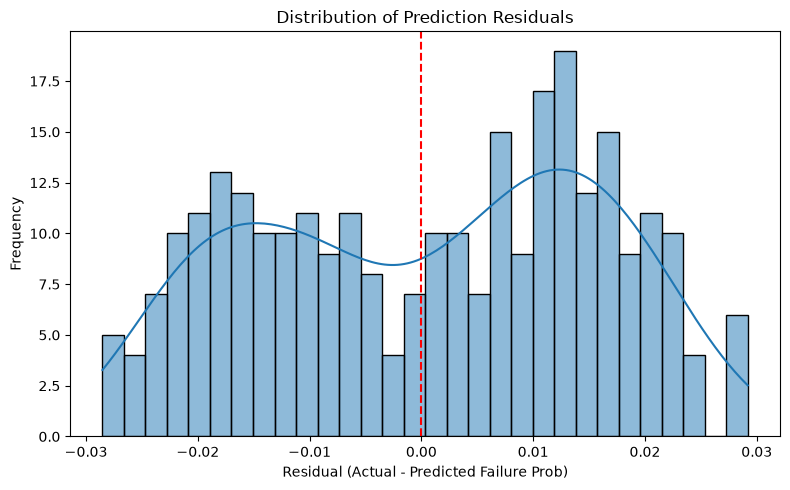

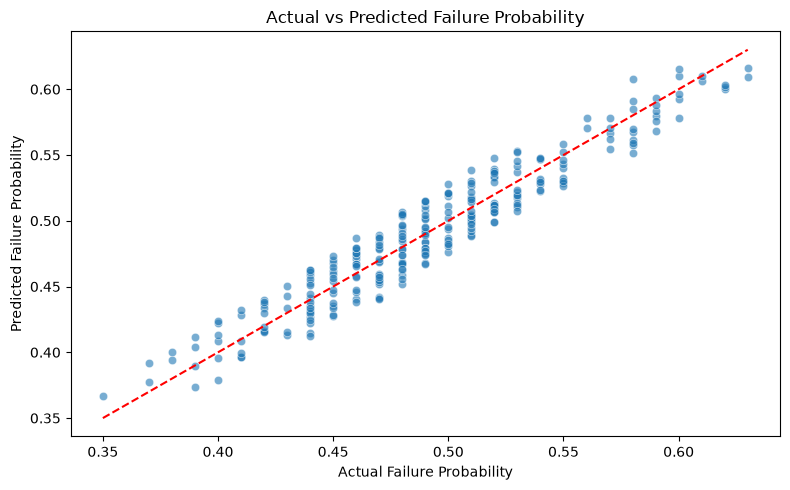

In [12]:
y_pred_final = final_model.predict(X_test_r)
residuals = y_test_r - y_pred_final

plt.figure(figsize=(8, 5))
sns.histplot(residuals, kde=True, bins=30)
plt.axvline(x=0, color="red", linestyle="--")
plt.title("Distribution of Prediction Residuals")
plt.xlabel("Residual (Actual - Predicted Failure Prob)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(x=y_test_r, y=y_pred_final, alpha=0.6)
plt.plot([y_test_r.min(), y_test_r.max()], [y_test_r.min(), y_test_r.max()], color="red", linestyle="--")
plt.title("Actual vs Predicted Failure Probability")
plt.xlabel("Actual Failure Probability")
plt.ylabel("Predicted Failure Probability")
plt.tight_layout()
plt.show()

## Export

In [13]:
MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(exist_ok=True, parents=True)

safe_name = final_model_name.split(" ")[0].lower().replace("(", "").replace(")", "")
MODEL_PATH = MODELS_DIR / f"best_{safe_name}_regression_model.joblib"

joblib.dump(final_model, MODEL_PATH)
print(f"Successfully saved at: {MODEL_PATH}")

Successfully saved at: D:\Projects\smart-manufacturing-maintenance\models\best_linear_regression_model.joblib


## Conclusion

This notebook established a physically grounded regression pipeline through causal reasoning and systematic model evaluation:

- **Causally Sound Feature Selection**: Operational features (`Technician_Availability_pct`, `Downtime_Cost_USD`, `Inspection_Duration_min`) were excluded despite increasing R² from 0.920 to 0.997. Because operational metrics cannot physically cause mechanical degradation, their correlation with `Failure_Prob` stems from target construction rather than physical dependency. Additionally, `Pressure_Bar` (no signal) and `Resource_Risk` (redundant) were dropped.

- Linear Regression outperformed both Random Forest (test R² = 0.901) and Gradient Boosting (test R² = 0.908), even when tree-based models were given an explicit interaction term (`Severity_Index`). Ridge regression yielded identical performance due to minimal multicollinearity, favoring the simpler unregularized linear model.

**Final Result**: The streamlined Linear Regression model achieved a **Test R² of 0.920** using only three physical sensors (`Temp_C`, `Vibration_mm_s`, `Acoustic_dB`). While lower than earlier non-causal iterations (0.997), this benchmark represents a defensible, production-ready model driven entirely by true physical signals.